<div style="border-left:7px solid #1A59FD; background:#F3F6FF; padding:16px 20px; border-radius:4px; font-family:Segoe UI, Arial, sans-serif;">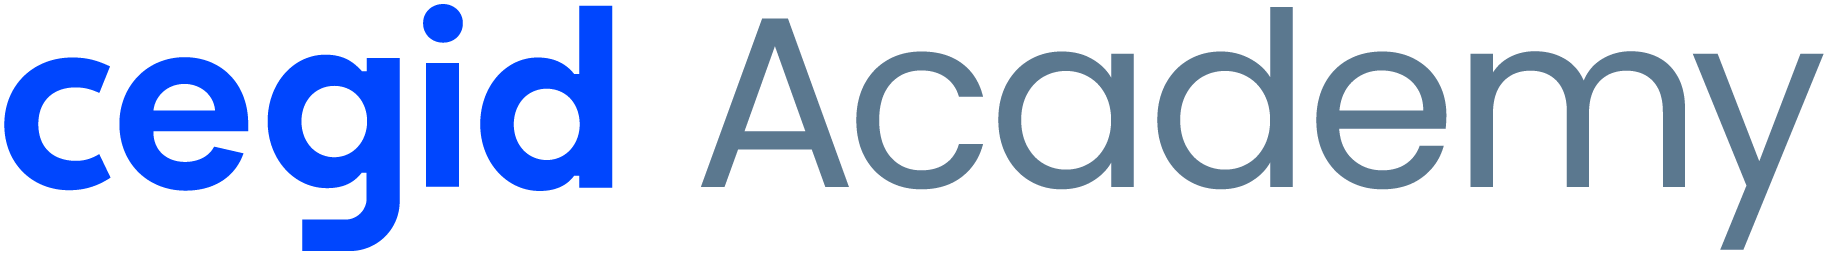<div style="font-size:22px; font-weight:700; color:#1A59FD; line-height:1.2;">Fase 3 &middot; Preparação dos Dados</div><div style="font-size:14px; color:#0A2540; margin-top:4px;">Implementação de Modelos Analíticos com Python &nbsp;&middot;&nbsp; Projeto CRISP-DM · <i>Data Preparation</i> &nbsp;&middot;&nbsp; Versão <b>formandos</b> &nbsp;&middot;&nbsp; Apoio: <b>M3.01 · M3.02</b></div><div style="margin-top:10px;"><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">1. Entendimento do Negócio</span><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">2. Entendimento dos Dados</span><span style="display:inline-block;background:#1A59FD;color:#FFFFFF;font-weight:600;border:1px solid #1A59FD;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">3. Preparação dos Dados</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">4. Modelação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">5. Avaliação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">6. Deployment</span></div></div>

#### Identificação do projeto

| Campo | Preenchimento |
|---|---|
| Projeto | Previsão da intenção de mudança de emprego |
| Grupo | Não indicado nos ficheiros fornecidos |
| Formandos | Não indicados nos ficheiros fornecidos |
| Data da revisão | 14/10/2026 |
| Dataset | `Data/input/Dados_RH_Mudanca_Emprego.csv` |

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Objetivo</div>Transformar dados brutos em dados <b>modeláveis</b>: garantir qualidade, reduzir ruído e evitar enviesamentos. É tipicamente a fase que consome <b>60–80% do tempo</b> do projeto. Todas as decisões devem vir da síntese da Fase 2.</div>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Data leakage</div><b>Regra de ouro contra o <i>data leakage</i>:</b> qualquer transformação que <b>aprende parâmetros</b> dos dados (média/mediana da imputação, categorias do encoding, média e desvio do scaling, componentes do PCA, limites de outliers, target encoding) deve ser ajustada <b>apenas no conjunto de treino</b> e depois aplicada ao teste. Por isso, a divisão treino/teste é feita <b>antes</b> dessas transformações.</div>

**Ordem recomendada (M3)**

1. Seleção de dados → 2. Limpeza determinística → 3. **Separação treino/teste** → 4. Feature engineering → 5. Valores em falta → 6. Outliers → 7. Encoding → 8. Scaling → 9. Redução de dimensionalidade → 10. Pipeline final → 11. Exportação

### 0. Configuração
<hr>

Usar **a mesma configuração** do notebook 02.

**0.1 Bibliotecas**
- `numpy`, `pandas`, `matplotlib`, `seaborn`, `json`, `pathlib`.
- Do scikit-learn: `train_test_split`, encoders (`OneHotEncoder`, `LabelEncoder`, `OrdinalEncoder`), scalers, imputers (`SimpleImputer`, `KNNImputer`), seleção (`VarianceThreshold`, `SelectKBest`, `RFE`), `PCA`, `Pipeline` e `ColumnTransformer`.

In [1]:
%matplotlib inline
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE, SelectKBest, VarianceThreshold, f_classif
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (MaxAbsScaler, MinMaxScaler, OneHotEncoder,
                                   OrdinalEncoder, PowerTransformer,
                                   QuantileTransformer, RobustScaler, StandardScaler)

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

**0.2 Configuração do projeto** — os **mesmos** valores do notebook 02 (`PROJETO`, `DATA_PATH`, `TARGET`, `PROBLEM_TYPE`, `ID_COLS`, `RANDOM_STATE`, `TEST_SIZE`).

In [2]:
PROJETO = 'RH_Mudanca_Emprego'
DATA_PATH = Path('Data/input/Dados_RH_Mudanca_Emprego.csv')
TARGET = 'procura_mudanca_emprego'
PROBLEM_TYPE = 'classificacao'
ID_COLS = ['id_candidato']
RANDOM_STATE = 42
TEST_SIZE = 0.2

**0.3 Estrutura de pastas** — igual ao notebook 02 (`Data/input`, `Data/output`, `Data/analytics`, `Data/models`).

In [3]:
for pasta in ('Data/input', 'Data/output', 'Data/analytics', 'Data/models'):
    Path(pasta).mkdir(parents=True, exist_ok=True)
print('Pastas do projeto verificadas.')

numero_figura = 0
# A proteção impede que uma nova execução desta célula envolva plt.show outra vez.
if not getattr(plt.show, '_projeto_rh_guardado', False):
    mostrar_figura = plt.show
    def guardar_e_mostrar(*args, **kwargs):
        global numero_figura
        for numero in plt.get_fignums():
            numero_figura += 1
            plt.figure(numero).savefig(f'Data/analytics/03_grafico_{numero_figura:02d}.png',
                                       dpi=150, bbox_inches='tight')
        mostrar_figura(*args, **kwargs)
        plt.close('all')
    guardar_e_mostrar._projeto_rh_guardado = True
    plt.show = guardar_e_mostrar
print('Guarda de figuras ativa.')


Pastas do projeto verificadas.
Guarda de figuras ativa.


**0.4 Carregar os dados**
- Ler o dataset original para `df_raw` e trabalhar numa cópia `df` (o original nunca é alterado).

In [4]:
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()
print('Dimensão:', df.shape)
display(df.head(4))

Dimensão: (19158, 14)


,id_candidato,cidade,indice_desenvolvimento_cidade,genero,experiencia_relevante,inscricao_universidade,nivel_educacao,area_formacao,anos_experiencia,dimensao_empresa,tipo_empresa,anos_desde_ultimo_emprego,horas_formacao,procura_mudanca_emprego
0,760695,Zona_049,0.910,NaN,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",6 anos,500 a 999,Empresa privada,1 ano,21,Não
1,789493,Zona_006,0.920,Feminino,Com experiência relevante,Não inscrito,Mestrado,Humanidades,Mais de 20 anos,100 a 500,Startup financiada,2 anos,74,Não
2,211612,Zona_007,0.924,NaN,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",9 anos,10 a 49,Empresa privada,1 ano,94,Não
3,521686,Zona_065,0.624,Masculino,Com experiência relevante,Não inscrito,Mestrado,"Ciência, Tecnologia, Engenharia e Matemática",15 anos,10000 ou mais,Empresa privada,1 ano,75,Não


### 1. Seleção de dados
<hr>

**Descrever que dados serão utilizados no modelo:**

- Que variáveis serão consideradas? Quais serão removidas e porquê?
- Colunas irrelevantes (identificadores, texto livre sem valor, colunas constantes)?
- Variáveis redundantes (a mesma informação noutra forma, ex.: `Attrition` e `AttritionFlag`)?
- Variáveis que **revelam o target** ou que não existiriam no momento da previsão (*leakage*)?
- O dataset será filtrado (por país, período, categoria)?

***Objetivo:*** definir claramente o subconjunto de dados a utilizar.

**1.1 Seleção de dados**
- Remover as colunas irrelevantes, redundantes ou que revelam o alvo (decididas na Fase 2) — `drop(columns=...)`.
- Aplicar filtros de linhas, se fizer sentido.
- Os identificadores (`ID_COLS`) podem ficar no DataFrame para rastreabilidade, mas não vão entrar no modelo.

In [5]:
# A análise da Fase 2 só justificou excluir o identificador do modelo.
# Mantemo-lo em df para rastreabilidade até à divisão treino/teste.


##### Análise e Interpretação

**Resposta:** Mantêm-se as variáveis explicativas da Fase 2. `id_candidato` é um identificador e será excluído de `X` antes da divisão. Não há evidência nesta fase de colunas que revelem o alvo, nem motivo para filtrar linhas. `cidade` é mantida: apesar de ter muitas categorias, pode conter informação que o índice de desenvolvimento não resume.

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Exemplo HR (regressão de <code>MonthlyIncome</code>): foram removidos <code>EmployeeID</code> (identificador), <code>Attrition</code> (redundante) e <code>AttritionFlag</code> (rótulo de saída que enviesaria a estimação salarial).</div>

### 2. Limpeza determinística (antes da divisão)
<hr>

Correções que **não aprendem nada com os dados** e podem ser feitas no dataset completo:

- **Duplicados**: remover os que são erros de registo
- **Tipos de dados**: converter texto para número/data, números para categoria
- **String processing**: remover espaços, uniformizar maiúsculas/minúsculas, corrigir categorias
- **Date/Time processing**: extrair ano, mês, dia da semana, fim de semana, diferenças entre datas
- **Códigos de missing disfarçados** (999, −1, `0` impossível) → `NaN` verdadeiro
- **Colunas redundantes**: a mesma informação noutra forma — e atenção a variáveis que são o **alvo disfarçado** (no Titanic, `alive`) → removê-las é prevenção de *leakage*
- **Inconsistências**: valores impossíveis (negativos, % > 100) → `NaN`
- **Target**: garantir que está codificado (ex.: `"Yes"/"No"` → `1/0`)

> **Determinística** = regra fixa definida por vocês (ex.: `999 → NaN`, `"hr " → "HR"`). Se a regra usa uma estatística dos dados (mediana, quantis, frequências, data mínima do dataset), deixa de ser determinística e passa para depois da divisão.

***Objetivo:*** garantir qualidade e coerência dos dados.

**2.1 Duplicados**
- Remover duplicados (`drop_duplicates`) e indicar quantos foram removidos.

In [6]:
duplicados = int(df.duplicated().sum())
ids_repetidos = int(df['id_candidato'].duplicated().sum())
print('Linhas duplicadas:', duplicados, '| Identificadores repetidos:', ids_repetidos)
if ids_repetidos:
    raise ValueError('Rever candidatos repetidos antes de dividir os dados.')
df = df.drop_duplicates().copy()

Linhas duplicadas: 0 | Identificadores repetidos: 0


##### Análise e Interpretação

**Resposta:** A Fase 2 não encontrou duplicados integrais nem identificadores repetidos. 

**2.2 String processing (M3.01)**
- Nas variáveis de texto: remover espaços (`str.strip`), espaços repetidos (`str.replace(r"\s+", " ", regex=True)`), uniformizar maiúsculas/minúsculas e corrigir categorias escritas de formas diferentes (`replace`).
- (Se aplicável) extrair informação com regex (`str.extract`).

In [7]:
colunas_texto = df.select_dtypes(include=['object', 'string']).columns.difference([TARGET])
for coluna in colunas_texto:
    texto = (df[coluna].astype('string').str.strip()
             .str.replace(r'\s+', ' ', regex=True).replace('', pd.NA))
    df[coluna] = texto.astype(object).where(texto.notna(), np.nan)
print('Colunas de texto normalizadas:', colunas_texto.tolist())

Colunas de texto normalizadas: ['anos_desde_ultimo_emprego', 'anos_experiencia', 'area_formacao', 'cidade', 'dimensao_empresa', 'experiencia_relevante', 'genero', 'inscricao_universidade', 'nivel_educacao', 'tipo_empresa']


##### Análise e Interpretação

**Resposta:** Foram removidos espaços no início e no fim e espaços repetidos nas colunas de texto. A Fase 2 não identificou categorias duplicadas por diferenças de escrita; preservaram-se as designações originais para manter a leitura dos resultados.

**2.3 Tipos de dados e datas (M3.01)**
- Converter tipos errados (`pd.to_datetime`, `astype`).
- Se houver datas: criar ano, mês, dia da semana, fim de semana, dias desde uma data de referência **fixa** (ex.: a data de início do contrato — não a data mínima do dataset) (`.dt`).

In [8]:
# Valores extremos: "<1" será 0 e ">20" será 21

texto_experiencia = df["anos_experiencia"].astype("string")

anos = pd.to_numeric(
    texto_experiencia.str.extract(r"(\d+)", expand=False),
    errors="coerce"
)

anos = anos.mask(
    texto_experiencia.eq("Menos de 1 ano").fillna(False),
    0
)

anos = anos.mask(
    texto_experiencia.eq("Mais de 20 anos").fillna(False),
    21
)

df["anos_experiencia_num"] = anos.astype("float64")

# Remover a coluna original apenas uma vez
df = df.drop(columns="anos_experiencia")

print(df["anos_experiencia_num"].describe())

print(
    "Datas no dataset:",
    [coluna for coluna in df.columns if "data" in coluna.lower()]
)

display(df.head())
print(df["anos_desde_ultimo_emprego"].dtype)

count    19093.000000
mean        10.100141
std          6.777024
min          0.000000
25%          4.000000
50%          9.000000
75%         16.000000
max         21.000000
Name: anos_experiencia_num, dtype: float64
Datas no dataset: []


,id_candidato,cidade,indice_desenvolvimento_cidade,genero,experiencia_relevante,inscricao_universidade,nivel_educacao,area_formacao,dimensao_empresa,tipo_empresa,anos_desde_ultimo_emprego,horas_formacao,procura_mudanca_emprego,anos_experiencia_num
0,760695,Zona_049,0.910,NaN,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",500 a 999,Empresa privada,1 ano,21,Não,6.0
1,789493,Zona_006,0.920,Feminino,Com experiência relevante,Não inscrito,Mestrado,Humanidades,100 a 500,Startup financiada,2 anos,74,Não,21.0
2,211612,Zona_007,0.924,NaN,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",10 a 49,Empresa privada,1 ano,94,Não,9.0
3,521686,Zona_065,0.624,Masculino,Com experiência relevante,Não inscrito,Mestrado,"Ciência, Tecnologia, Engenharia e Matemática",10000 ou mais,Empresa privada,1 ano,75,Não,15.0
4,146611,Zona_030,0.698,Masculino,Sem experiência relevante,Não inscrito,Mestrado,"Ciência, Tecnologia, Engenharia e Matemática",500 a 999,ONG,1 ano,157,Não,12.0


object


##### Análise e Interpretação

**Resposta:** `anos_experiencia` foi convertido numa escala ordinal numérica. Os códigos 0 e 21 representam, respetivamente, “menos de 1 ano” e “mais de 20 anos”; o último não deve ser interpretado como duração exata. `anos_desde_ultimo_emprego` fica categórica porque inclui “Nunca”. Não existem datas para derivar variáveis temporais.

**2.4 Códigos de missing e inconsistências (M3.01)**
- Converter códigos de missing disfarçados (999, −1, 0 impossível) e valores impossíveis em `np.nan`.

In [9]:
# O perfil observado não contém códigos especiais de ausência (999, -1).
# Valores fisicamente impossíveis são convertidos em nulos por regra fixa.
regras_invalidos = {
    'indice_desenvolvimento_cidade': lambda s: s.lt(0) | s.gt(1),
    'horas_formacao': lambda s: s.lt(0),
    'anos_experiencia_num': lambda s: s.lt(0),
}
for coluna, regra in regras_invalidos.items():
    mascara = regra(df[coluna]).fillna(False)
    print(f'{coluna}: {int(mascara.sum())} valores impossíveis convertidos em nulos')
    df.loc[mascara, coluna] = np.nan

indice_desenvolvimento_cidade: 0 valores impossíveis convertidos em nulos
horas_formacao: 0 valores impossíveis convertidos em nulos
anos_experiencia_num: 0 valores impossíveis convertidos em nulos


##### Análise e Interpretação

**Resposta:** A análise anterior não encontrou códigos de ausência disfarçados. O código apenas transforma em nulos valores impossíveis: índice fora de [0, 1], horas negativas ou experiência negativa. As ausências originais serão tratadas no pipeline ajustado no treino.

**2.5 [Classificação] Codificar o alvo**
- Se o target estiver em texto, convertê-lo em números com `LabelEncoder` e mostrar o mapeamento (`classes_`).
- Garantir que a **classe de interesse** (a que se quer detetar: sair, fraude, doença…) fica codificada como `1`: precision, recall e F1 usam `pos_label=1` por omissão. O `LabelEncoder` ordena alfabeticamente — em binário, um `map` explícito (ex.: `{"No": 0, "Yes": 1}`) é mais seguro.

In [10]:
df[TARGET] = df[TARGET].astype('string').str.strip().str.casefold().map({'não': 0, 'sim': 1})
if df[TARGET].isna().any():
    raise ValueError('O alvo contém valores inesperados; verificar as categorias antes de prosseguir.')
df[TARGET] = df[TARGET].astype('int8')
print('Mapeamento do alvo: Não → 0, Sim → 1')
display(df[TARGET].value_counts().rename(index={0: 'Não (0)', 1: 'Sim (1)'}))

Mapeamento do alvo: Não → 0, Sim → 1


procura_mudanca_emprego
Não (0)    14381
Sim (1)     4777
Name: count, dtype: int64

In [11]:
df.head(5)

,id_candidato,cidade,indice_desenvolvimento_cidade,genero,experiencia_relevante,inscricao_universidade,nivel_educacao,area_formacao,dimensao_empresa,tipo_empresa,anos_desde_ultimo_emprego,horas_formacao,procura_mudanca_emprego,anos_experiencia_num
0,760695,Zona_049,0.910,NaN,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",500 a 999,Empresa privada,1 ano,21.0,0,6.0
1,789493,Zona_006,0.920,Feminino,Com experiência relevante,Não inscrito,Mestrado,Humanidades,100 a 500,Startup financiada,2 anos,74.0,0,21.0
2,211612,Zona_007,0.924,NaN,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",10 a 49,Empresa privada,1 ano,94.0,0,9.0
3,521686,Zona_065,0.624,Masculino,Com experiência relevante,Não inscrito,Mestrado,"Ciência, Tecnologia, Engenharia e Matemática",10000 ou mais,Empresa privada,1 ano,75.0,0,15.0
4,146611,Zona_030,0.698,Masculino,Sem experiência relevante,Não inscrito,Mestrado,"Ciência, Tecnologia, Engenharia e Matemática",500 a 999,ONG,1 ano,157.0,0,12.0


### 3. Separação dos dados (treino / teste)
<hr>

- Proporção: 80/20 ou 70/30 (compromisso entre dados para aprender e dados para validar)
- `random_state` → reprodutibilidade
- `stratify=y` em classificação → mantém a proporção das classes em treino e teste
- O **conjunto de teste fica "intocado"** até à avaliação do modelo final (Fase 4, secção 7, e Fase 5): não é usado para escolher variáveis, estratégias de preparação, modelos, hiperparâmetros ou limiares
- **Dados temporais** → divisão cronológica (dados ordenados por data e `shuffle=False`, ou corte por data) em vez de aleatória
- **Várias linhas por entidade** → divisão por grupo (`GroupShuffleSplit`), para a mesma entidade não ficar no treino e no teste
- A validação cruzada é feita na Fase 4, **apenas com o treino**

***Objetivo:*** garantir uma avaliação justa e evitar *data leakage*.

**3.1 [Classificação / Regressão] Separar X e y e dividir treino/teste**
- `X` = todas as colunas exceto o target; `y` = target.
- `train_test_split` com `test_size=TEST_SIZE`, `random_state=RANDOM_STATE` e `stratify=y` em classificação.
- Mostrar as dimensões de `X_train` e `X_test`.

In [12]:
X = df.drop(columns=[TARGET] + ID_COLS)
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print('Treino:', X_train.shape, 'Teste:', X_test.shape)
assert X_train.index.intersection(X_test.index).empty

Treino: (15326, 12) Teste: (3832, 12)


**3.2 [Classificação] Verificar a estratificação**
- Comparar a proporção das classes no dataset, no treino e no teste.

In [13]:
proporcoes = pd.DataFrame({
    'total': y.value_counts(normalize=True),
    'treino': y_train.value_counts(normalize=True),
    'teste': y_test.value_counts(normalize=True),
}).mul(100).round(2)
display(proporcoes)

,total,treino,teste
procura_mudanca_emprego,,,
0,75.07,75.06,75.08
1,24.93,24.94,24.92


##### Análise e Interpretação

**Resposta:** A divisão estratificada preserva aproximadamente a proporção de cada classe (cerca de 75% “Não” e 25% “Sim”) nos dois conjuntos. O teste será usado apenas na avaliação final; as escolhas de preparação são feitas com o treino.

**3.3 [Clustering] Dados para clustering**
- Não há target nem divisão treino/teste: usar o dataset completo como `X_train` (e `X_test = None`).

In [14]:
print('Não aplicável: este projeto é de classificação supervisionada.')

Não aplicável: este projeto é de classificação supervisionada.


### 4. Engenharia de variáveis (Feature Engineering)
<hr>

Criar novas variáveis a partir das existentes para **extrair mais informação** dos dados que já temos:

| Tipo | Exemplo | Para que serve |
|---|---|---|
| Razão | `petal_ratio = petal_length / petal_width` · `fare_per_person = fare / family_size` | captar proporções |
| Soma / diferença | `family_size = sibsp + parch + 1` | agregar informação relacionada |
| Indicador binário | `is_alone = 1 se family_size == 1` | simplificar uma condição relevante |
| Transformação | `log_fare = log(fare + 1)` | reduzir assimetria |
| Discretização | `age_group = child / adult / senior` (`pd.cut`) | categorias interpretáveis |
| Interação | `area = length * width` | efeitos combinados |
| Temporal | ano, mês, dia da semana, antiguidade | padrões temporais |

> **Atenção:** `pd.cut` com limites fixos escolhidos por vocês é determinístico; `pd.qcut` (quantis), agregados por grupo (ex.: média salarial por departamento) e contagens/frequências **aprendem com os dados** → calcular no treino e aplicar ao teste. Nunca usar o target para criar variáveis (exceto o target encoding controlado da secção 7).

- Qual a motivação de cada variável? Existe fundamentação teórica ou empírica (Fase 2)?

***Objetivo:*** melhorar a capacidade explicativa do modelo.

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Regras <b>determinísticas</b> (que não aprendem com os dados) podem ser aplicadas da mesma forma a treino e teste através de uma função. A análise do impacto das novas variáveis faz-se <b>no treino</b>.</div>

**4.1 Feature engineering (M3.01)**
- Criar uma função `criar_features(data)` com as variáveis derivadas escolhidas (razões, somas/diferenças, indicadores binários, `log1p`, binning com `pd.cut`, interações, componentes de datas).
- Aplicá-la **da mesma forma** a `X_train` e `X_test` e listar as novas variáveis.

In [15]:
def criar_features(data):
    resultado = data.copy()
    resultado['log_horas_formacao'] = np.log1p(resultado['horas_formacao'])
    resultado['pouca_experiencia'] = resultado['anos_experiencia_num'].le(2).astype(float)
    resultado.loc[resultado['anos_experiencia_num'].isna(), 'pouca_experiencia'] = np.nan
    resultado['universidade_tempo_inteiro'] = (
        resultado['inscricao_universidade'].eq('Curso a tempo inteiro').astype(float)
    )
    resultado.loc[resultado['inscricao_universidade'].isna(), 'universidade_tempo_inteiro'] = np.nan
    return resultado

colunas_antes = set(X_train.columns)
X_train = criar_features(X_train)
X_test = criar_features(X_test)
FEATURES_NOVAS = sorted(set(X_train.columns) - colunas_antes)
print('Novas variáveis:', FEATURES_NOVAS)
display(X_train[FEATURES_NOVAS].head())

Novas variáveis: ['log_horas_formacao', 'pouca_experiencia', 'universidade_tempo_inteiro']


,log_horas_formacao,pouca_experiencia,universidade_tempo_inteiro
17832,4.394449,0.0,0.0
17654,4.369448,0.0,0.0
13422,5.525453,0.0,0.0
13381,4.060443,0.0,0.0
15763,4.077537,0.0,0.0


##### Análise e Interpretação

**Resposta:** `log_horas_formacao` reduz a assimetria observada na Fase 2. `pouca_experiencia` representa até 2 anos de experiência, associados a taxas mais altas de procura. `universidade_tempo_inteiro` destaca a categoria que teve uma taxa de procura elevada. São regras fixas aplicadas da mesma forma aos dois conjuntos; valores em falta continuam em falta.

**4.2 [Classificação] Avaliar as novas variáveis (no treino)**
- Para cada nova variável: `barplot` da taxa do target (se tiver poucos valores) ou boxplot por classe.

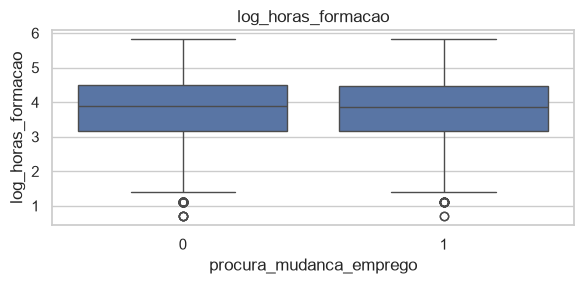

,taxa_sim,n
pouca_experiencia,,
0.0,0.231309,13536
1.0,0.386207,1740


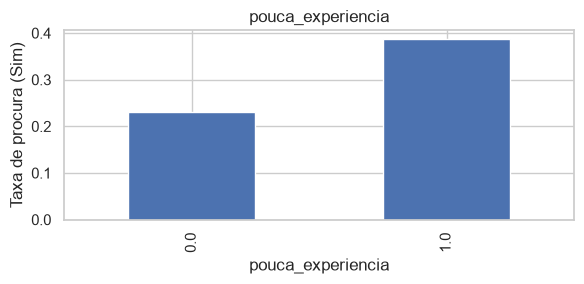

,taxa_sim,n
universidade_tempo_inteiro,,
0.0,0.211718,12016
1.0,0.392013,3005


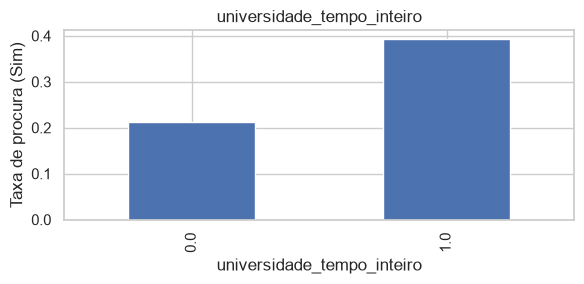

In [16]:
avaliacao_features = X_train[FEATURES_NOVAS].copy()
avaliacao_features[TARGET] = y_train
for coluna in FEATURES_NOVAS:
    fig, ax = plt.subplots(figsize=(6, 3))
    if avaliacao_features[coluna].nunique(dropna=True) <= 5:
        taxas = avaliacao_features.groupby(coluna)[TARGET].agg(['mean', 'count'])
        display(taxas.rename(columns={'mean': 'taxa_sim', 'count': 'n'}))
        taxas['mean'].plot.bar(ax=ax)
        ax.set_ylabel('Taxa de procura (Sim)')
    else:
        sns.boxplot(data=avaliacao_features, x=TARGET, y=coluna, ax=ax)
    ax.set_title(coluna)
    plt.tight_layout()
    plt.show()

##### Análise e Interpretação

**Resposta:** As taxas e distribuições acima permitem comparar as classes apenas no treino. As variáveis binárias resumem padrões já presentes nas variáveis originais; a transformação logarítmica das horas altera a escala, não cria informação nova. A melhoria preditiva terá de ser confirmada por validação cruzada na Fase 4.

**4.2 [Regressão] Avaliar as novas variáveis (no treino)**
- Correlação das novas variáveis numéricas com o target.

In [17]:
print('Não aplicável: o alvo é binário, não contínuo.')

Não aplicável: o alvo é binário, não contínuo.


##### Análise e Interpretação

**Resposta:** Não aplicável a este projeto de classificação.

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Atenção</div>Criar muitas colunas sem critério aumenta o ruído e o risco de <b>overfitting</b>. Nem todas as variáveis criadas melhoram o problema — mantenham apenas as que têm justificação.</div>

#### Definição das listas de variáveis

A partir daqui trabalha-se com listas explícitas de variáveis numéricas e categóricas (sem IDs nem target).

**4.3 Listas finais de variáveis**
- Criar `NUM_COLS` e `CAT_COLS` a partir de `X_train`, sem identificadores nem target.
- Ajustar manualmente, se necessário (ex.: numérica que é na verdade categórica).

In [18]:
NUM_COLS = X_train.select_dtypes(include='number').columns.tolist()
CAT_COLS = [c for c in X_train.columns if c not in NUM_COLS]
assert not (set(ID_COLS + [TARGET]) & set(NUM_COLS + CAT_COLS))
print('Numéricas:', NUM_COLS)
print('Categóricas:', CAT_COLS)

Numéricas: ['indice_desenvolvimento_cidade', 'horas_formacao', 'anos_experiencia_num', 'log_horas_formacao', 'pouca_experiencia', 'universidade_tempo_inteiro']
Categóricas: ['cidade', 'genero', 'experiencia_relevante', 'inscricao_universidade', 'nivel_educacao', 'area_formacao', 'dimensao_empresa', 'tipo_empresa', 'anos_desde_ultimo_emprego']


### 5. Valores em falta
<hr>

**Estratégias possíveis**

| Estratégia (M3.02) | Quando | Nota |
|---|---|---|
| Remover **linhas** (`dropna`) | poucos nulos, MCAR | perde dados |
| Remover **colunas** | coluna quase toda nula (ex.: `deck`) | perde a variável |
| Imputar **média** | numérica simétrica | sensível a outliers |
| Imputar **mediana** | numérica assimétrica | robusta |
| Imputar **moda** | categórica | — |
| Imputar **constante** | "Desconhecido" / 0 | preserva o "não sabido" |
| Imputar **por grupo** | há grupos informativos (ex.: mediana da idade por classe) | melhor estimativa |
| **KNNImputer** | relações entre variáveis | mais custoso |
| **IterativeImputer (MICE)** | missing complexo | modela cada coluna |
| **Indicador de missing** (`add_indicator=True`) | o facto de faltar é informativo | cria uma flag |

Os valores usados na imputação são calculados **no treino** (o imputer dentro do Pipeline garante isto).

**5.1 Valores em falta no treino**
- Tabela com nº e % de nulos por coluna em `X_train` (só as colunas com nulos).

In [19]:
nulos_treino = pd.DataFrame({
    'nulos': X_train.isna().sum(),
    'percentagem': 100 * X_train.isna().mean(),
}).query('nulos > 0').sort_values('nulos', ascending=False)
display(nulos_treino.round(2))

,nulos,percentagem
tipo_empresa,4921,32.11
dimensao_empresa,4773,31.14
genero,3584,23.39
area_formacao,2234,14.58
nivel_educacao,357,2.33
anos_desde_ultimo_emprego,337,2.20
inscricao_universidade,305,1.99
universidade_tempo_inteiro,305,1.99
anos_experiencia_num,50,0.33
pouca_experiencia,50,0.33


##### Análise e Interpretação

**Resposta:** As ausências mais relevantes são nas categorias `tipo_empresa`, `dimensao_empresa`, `genero` e `area_formacao`; há também poucas ausências em `anos_experiencia_num`. As novas variáveis binárias preservam as ausências das colunas de origem. A imputação será ajustada exclusivamente no treino.

**5.2 Comparar estratégias de imputação (M3.02)**
- Na variável numérica com mais nulos: comparar a distribuição original com a imputação pela média, pela mediana e com `KNNImputer` (tabela `describe` + `kdeplot`).
- (Opcional) Imputação por grupo com `groupby(...).transform("median")`: calcular as medianas por grupo em `X_train` e aplicá-las ao `X_test` com `map` — não usar `transform` no dataset completo nem no teste.

Variável comparada: anos_experiencia_num
Nota: KNN com uma só variável aproxima-se da média dos vizinhos disponíveis; esta comparação é apenas didática.


,count,mean,std,min,25%,50%,75%,max
original,15276.0,10.128,6.784,0.0,4.0,9.0,16.0,21.0
media,15326.0,10.128,6.773,0.0,4.0,9.0,16.0,21.0
mediana,15326.0,10.124,6.773,0.0,4.0,9.0,16.0,21.0
knn,15326.0,10.128,6.773,0.0,4.0,9.0,16.0,21.0


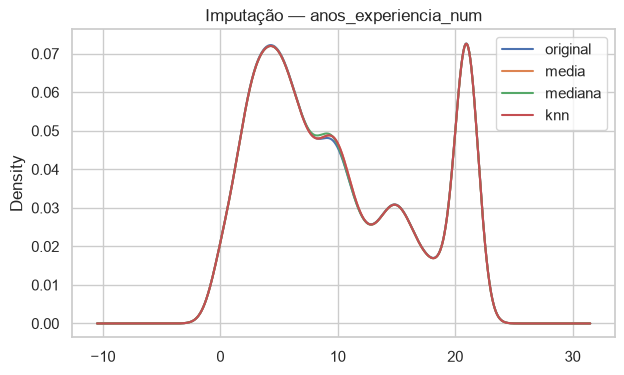

In [20]:
# Comparar numa variável quantitativa de origem; indicadores binários derivados
# também têm nulos, mas a sua KDE não é uma comparação útil de distribuições.
numericas_continuas = ['indice_desenvolvimento_cidade', 'anos_experiencia_num', 'horas_formacao']
num_com_nulos = X_train[numericas_continuas].isna().sum()
if num_com_nulos.max() > 0:
    coluna_nulos = num_com_nulos.idxmax()
    base = X_train[[coluna_nulos]].astype(float)
    comparacao = pd.DataFrame({
        'original': base[coluna_nulos],
        'media': SimpleImputer(strategy='mean').fit_transform(base).ravel(),
        'mediana': SimpleImputer(strategy='median').fit_transform(base).ravel(),
        'knn': KNNImputer(n_neighbors=5).fit_transform(base).ravel(),
    }, index=base.index)
    print('Variável comparada:', coluna_nulos)
    print('Nota: KNN com uma só variável aproxima-se da média dos vizinhos disponíveis;'
          ' esta comparação é apenas didática.')
    display(comparacao.describe().T.round(3))
    comparacao.plot.kde(figsize=(7, 4), title=f'Imputação — {coluna_nulos}')
    plt.show()
else:
    print('Não há variáveis numéricas com valores em falta.')

##### Análise e Interpretação

**Resposta:** A comparação é feita em `anos_experiencia_num`, a variável quantitativa original com mais ausências. As variáveis binárias derivadas ficam de fora deste gráfico porque a KDE não é adequada a dois valores discretos. Escolhe-se a mediana pela robustez; indicadores de ausência preservam a informação de que o valor era desconhecido. O KNN univariado acima não usa relações entre várias colunas.

**5.3 Estratégias escolhidas**
- Guardar em variáveis as decisões que vão para o Pipeline: `ESTRATEGIA_NUM` (`"mean"`, `"median"` ou `"knn"`), `ESTRATEGIA_CAT` (`"most_frequent"` ou `"constant"`) e `ADD_INDICATOR` (True/False).

In [21]:
ESTRATEGIA_NUM = 'median'
ESTRATEGIA_CAT = 'constant'
ADD_INDICATOR = True
print('Numéricas:', ESTRATEGIA_NUM, '| categóricas:', ESTRATEGIA_CAT,
      '| indicador de ausência numérica:', ADD_INDICATOR)

Numéricas: median | categóricas: constant | indicador de ausência numérica: True


### 6. Outliers
<hr>

- Foram identificados (IQR 1,5×, Z-score ±3, percentis 1%–99%)? Em que variáveis?
- São **erros** (corrigir/remover) ou **valores raros mas reais** (manter)?
- Que decisão foi tomada e qual o critério?

| Opção | Descrição |
|---|---|
| Manter | valores reais e informativos; usar modelos robustos (árvores) ou `RobustScaler` |
| Remover | apenas erros evidentes e **apenas no treino** |
| Limitar (*capping*) | `clip` aos limites IQR calculados no treino |
| *Winsorizing* | `clip` aos percentis 1% e 99% calculados no treino |
| Transformar | `np.log1p` para reduzir o efeito de valores extremos |

**Decisão (M3.02):** erro de medição → remover/corrigir; informação rara real → manter (capping/log preserva a observação sem a deixar dominar). Em variáveis assimétricas preferir **log** ou **RobustScaler** a remover.

**Nunca remover linhas do conjunto de teste:** o teste tem de representar os dados reais que o modelo vai encontrar.

**6.1 Deteção de outliers no treino**
- Para cada numérica: nº de outliers por IQR, Z-score e percentis (P1–P99), guardando os limites IQR calculados no treino.

In [22]:
limites_iqr = {}
linhas_outliers = []
for coluna in NUM_COLS:
    valores = X_train[coluna].dropna().astype(float)
    if valores.empty:
        continue
    q1, q3 = valores.quantile([0.25, 0.75])
    iqr = q3 - q1
    inf, sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    limites_iqr[coluna] = {'inferior': float(inf), 'superior': float(sup)}
    z = (valores - valores.mean()) / valores.std(ddof=0) if valores.std(ddof=0) else valores * 0
    p1, p99 = valores.quantile([0.01, 0.99])
    linhas_outliers.append({
        'variavel': coluna, 'IQR': int(((valores < inf) | (valores > sup)).sum()),
        'Z_3': int((z.abs() > 3).sum()),
        'P1_P99': int(((valores < p1) | (valores > p99)).sum()),
        'limite_inferior_IQR': inf, 'limite_superior_IQR': sup,
    })
tabela_outliers = pd.DataFrame(linhas_outliers).set_index('variavel')
display(tabela_outliers.round(2))

,IQR,Z_3,P1_P99,limite_inferior_IQR,limite_superior_IQR
variavel,,,,,
indice_desenvolvimento_cidade,13,13,207,0.47,1.19
horas_formacao,791,352,232,-74.50,185.50
anos_experiencia_num,0,0,0,-14.00,34.00
log_horas_formacao,84,7,232,1.21,6.45
pouca_experiencia,1740,0,0,0.00,0.00
universidade_tempo_inteiro,3005,0,0,0.00,0.00


##### Análise e Interpretação

**Resposta:** A tabela quantifica valores extremos com três regras distintas. Na Fase 2, os extremos do índice de desenvolvimento e das horas de formação foram considerados plausíveis. Os indicadores binários podem aparecer como outliers pelo IQR quando uma categoria é rara; isso não significa erro.

**6.2 Tratamento de outliers (se aplicável)**
- Aplicar a decisão tomada: capping (`clip` aos limites IQR), winsorizing (`clip` a P1–P99) ou `np.log1p`.
- Os limites são calculados **no treino** e aplicados **da mesma forma** ao teste.

In [23]:
# Não há prova de erros nas caudas; mantemos os valores originais.
# O log das horas e RobustScaler (abaixo) reduzem a influência dos extremos.
TRATAMENTO_OUTLIERS = 'manter'
parametros_fora_pipeline = {'tratamento_outliers': TRATAMENTO_OUTLIERS,
                             'limites_iqr_diagnostico': limites_iqr,
                             'mapeamentos_encoding': {}}
print('Decisão:', TRATAMENTO_OUTLIERS)

Decisão: manter


##### Análise e Interpretação

**Resposta:** Não foram eliminadas linhas nem aplicados limites de capping: os valores extremos parecem observações reais. `log_horas_formacao` e `RobustScaler` atenuam a influência das caudas. A decisão preserva a composição do treino e do teste.

### 7. Encoding de variáveis categóricas
<hr>

| Estratégia (M3.01) | Quando usar | Cuidado |
|---|---|---|
| **Label / Ordinal** | binárias ou ordinais (com ordem real); `LabelEncoder` no **alvo** | introduz ordem artificial em nominais |
| **One-Hot** | nominais com poucas categorias | aumenta a dimensionalidade; `handle_unknown="ignore"` evita erros com categorias novas |
| **Frequency** | nominais com muitas categorias | categorias com igual frequência colidem |
| **Target / Mean** | muitas categorias, com relação ao alvo | **data leakage** → ajustar **só no treino** |
| **Binary / Hashing** (avançado) | cardinalidade muito alta | menos interpretável |

`pd.get_dummies(drop_first=True)` serve para análises rápidas, mas não guarda as categorias do treino → num projeto preferir o `OneHotEncoder` dentro do Pipeline.

**7.1 Categorias por variável (treino)**
- Para cada categórica: nº de categorias e lista das categorias.

In [24]:
categorias = pd.DataFrame([
    {'variavel': c, 'n_categorias': X_train[c].nunique(dropna=True),
     'categorias': X_train[c].dropna().unique().tolist()}
    for c in CAT_COLS
])
display(categorias)

,variavel,n_categorias,categorias
0,cidade,123,"[Zona_065, Zona_014, Zona_049, Zona_025, Zona_..."
1,genero,3,"[Masculino, Feminino, Outro]"
2,experiencia_relevante,2,"[Com experiência relevante, Sem experiência re..."
3,inscricao_universidade,3,"[Não inscrito, Curso a tempo parcial, Curso a ..."
4,nivel_educacao,5,"[Licenciatura, Ensino Secundário, Mestrado, En..."
5,area_formacao,6,"[Ciência, Tecnologia, Engenharia e Matemática,..."
6,dimensao_empresa,8,"[Menos de 10, 10000 ou mais, 10 a 49, 100 a 50..."
7,tipo_empresa,6,"[Empresa privada, Startup em fase inicial, Sta..."
8,anos_desde_ultimo_emprego,6,"[1 ano, Mais de 4 anos, 3 anos, Nunca, 4 anos,..."


##### Análise e Interpretação

**Resposta:** `cidade` tem cardinalidade relativamente alta; as restantes categóricas têm poucos níveis. Usa-se One-Hot no pipeline para todas elas, incluindo educação e dimensão da empresa, para evitar impor distâncias artificiais entre categorias. A possibilidade de usar ordem explícita é demonstrada na secção 7.4.

**7.2 One-Hot Encoding**
- `OneHotEncoder(handle_unknown="ignore")` ajustado no treino; mostrar as colunas geradas (`get_feature_names_out`).

In [25]:
imputador_cat_demo = SimpleImputer(strategy='constant', fill_value='Desconhecido')
cat_treino_demo = imputador_cat_demo.fit_transform(X_train[CAT_COLS])
encoder_demo = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoder_demo.fit(cat_treino_demo)
nomes_one_hot = encoder_demo.get_feature_names_out(CAT_COLS)
print(f'Colunas criadas pelo One-Hot: {len(nomes_one_hot)}')
display(pd.Series(nomes_one_hot, name='coluna').to_frame().head(30))

Colunas criadas pelo One-Hot: 169


,coluna
0,cidade_Zona_001
1,cidade_Zona_002
2,cidade_Zona_003
3,cidade_Zona_004
4,cidade_Zona_005
5,cidade_Zona_006
6,cidade_Zona_007
7,cidade_Zona_008
8,cidade_Zona_009
9,cidade_Zona_010


##### Análise e Interpretação

**Resposta:** O número de colunas criadas é mostrado acima; a cidade representa a maior parte delas. `handle_unknown='ignore'` permite transformar um candidato de uma cidade ou categoria ausente do treino sem falhar (essa categoria fica com zeros no respetivo bloco).

**7.3 Outras estratégias de encoding (M3.01)**
- Binária: `(X["col"] == "valor").astype(int)`.
- Frequency encoding: `map(value_counts(normalize=True))` calculado no treino.
- Target encoding: `y_train.groupby(X_train[col]).mean()` — **só no treino**, depois aplicado ao teste.

In [26]:
# Exemplos calculados apenas no treino; não entram no pipeline final.
binaria = X_train['experiencia_relevante'].eq('Sem experiência relevante').astype('Int64')
binaria = binaria.mask(X_train['experiencia_relevante'].isna())
frequencias_cidade = X_train['cidade'].value_counts(normalize=True)
frequency_demo = X_train['cidade'].map(frequencias_cidade)
print('Exemplo binário:')
display(binaria.value_counts(dropna=False))
print('Frequency encoding da cidade (amostra):')
display(frequency_demo.head())
print('Target encoding não é usado: exigiria codificação fora do fold para evitar leakage na validação cruzada.')

Exemplo binário:


experiencia_relevante
0    11046
1     4280
Name: count, dtype: Int64

Frequency encoding da cidade (amostra):


17832    0.140350
17654    0.070599
13422    0.082148
13381    0.082148
15763    0.004698
Name: cidade, dtype: float64

Target encoding não é usado: exigiria codificação fora do fold para evitar leakage na validação cruzada.


##### Análise e Interpretação

**Resposta:** O One-Hot é simples e seguro para este tamanho de dados. Frequency encoding perderia a identidade de cidades com frequências iguais. Target encoding sem validação cruzada interna aprende diretamente as taxas do alvo de cada categoria e pode criar fuga de informação; por isso não é aplicado.

**7.4 (Se aplicável) Variáveis ordinais**
- `OrdinalEncoder` com a ordem das categorias explícita.

In [27]:
ordem_educacao = ['Ensino Básico', 'Ensino Secundário', 'Licenciatura',
                  'Mestrado', 'Doutoramento']
ordinal_demo = OrdinalEncoder(categories=[ordem_educacao],
                              handle_unknown='use_encoded_value', unknown_value=-1)
amostra_ordinal = X_train[['nivel_educacao']].dropna()
codigos_educacao = ordinal_demo.fit_transform(amostra_ordinal)
display(pd.DataFrame({'categoria': ordem_educacao, 'codigo': range(len(ordem_educacao))}))
print('Linhas demonstrativas codificadas:', len(codigos_educacao))
print('A educação mantém-se em One-Hot no pipeline final.')

,categoria,codigo
0,Ensino Básico,0
1,Ensino Secundário,1
2,Licenciatura,2
3,Mestrado,3
4,Doutoramento,4


Linhas demonstrativas codificadas: 14969
A educação mantém-se em One-Hot no pipeline final.


<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Atenção</div><b>Target Encoding</b> (substituir a categoria pela média do target) usa o próprio target: se for calculado no dataset completo, a informação do teste passa para o treino (<i>leakage</i>). Se o usarem, calculem-no <b>só no treino</b> e apliquem o mapeamento ao teste. Encodings feitos fora do Pipeline (Frequency, Target, Ordinal) têm de ser aplicados da mesma forma a treino e teste <b>antes</b> da secção 10 — e a variável resultante passa para <code>NUM_COLS</code>. Mesmo calculado só no treino, o target encoding manual usa o alvo da <b>própria linha</b>, o que produz overfitting e uma validação cruzada otimista na Fase 4. Alternativa recomendada: <code>TargetEncoder</code> do scikit-learn (versão ≥ 1.3) dentro do Pipeline, que faz <i>cross-fitting</i> internamente.</div>

### 8. Scaling (normalização / escalonamento)
<hr>

| Método (M3.02) | O que faz | Sensível a outliers? | Quando usar |
|---|---|---|---|
| `StandardScaler` | média 0, desvio padrão 1 | sim | uso geral; dados aproximadamente normais |
| `MinMaxScaler` | intervalo [0, 1] | **muito** | quando é preciso um intervalo fixo |
| `RobustScaler` | usa mediana e IQR | não | dados com outliers / assimétricos (usado no pipeline das aulas) |
| `MaxAbsScaler` | divide pelo máximo absoluto | sim | dados esparsos |
| `Normalizer` | normaliza **por linha** (não por coluna) | — | casos específicos (ex.: texto) |
| `PowerTransformer` (Yeo-Johnson) / `QuantileTransformer` | aproximam da normal | reduzem o efeito | corrigir assimetria |

**Precisam de scaling:** KNN, Regressão Logística, SVM, redes neuronais, K-Means, PCA (baseados em distância ou gradiente).
**Não precisam:** árvores de decisão e Random Forest.

**8.1 Comparar scalers (M3.02)**
- Numa variável (a mais assimétrica/com outliers), comparar Standard, MinMax, Robust, MaxAbs, PowerTransformer e QuantileTransformer: tabela `describe` e histogramas.

,count,mean,std,min,25%,50%,75%,max
original,15326.0,65.368,59.815,1.000,23.000,47.000,88.000,336.000
Standard,15326.0,0.000,1.000,-1.076,-0.708,-0.307,0.378,4.525
MinMax,15326.0,0.192,0.179,0.000,0.066,0.137,0.260,1.000
Robust,15326.0,0.283,0.920,-0.708,-0.369,0.000,0.631,4.446
MaxAbs,15326.0,0.195,0.178,0.003,0.068,0.140,0.262,1.000
Power,15326.0,0.000,1.000,-2.746,-0.708,0.006,0.706,2.448
Quantile,15326.0,0.500,0.290,0.000,0.248,0.497,0.749,1.000


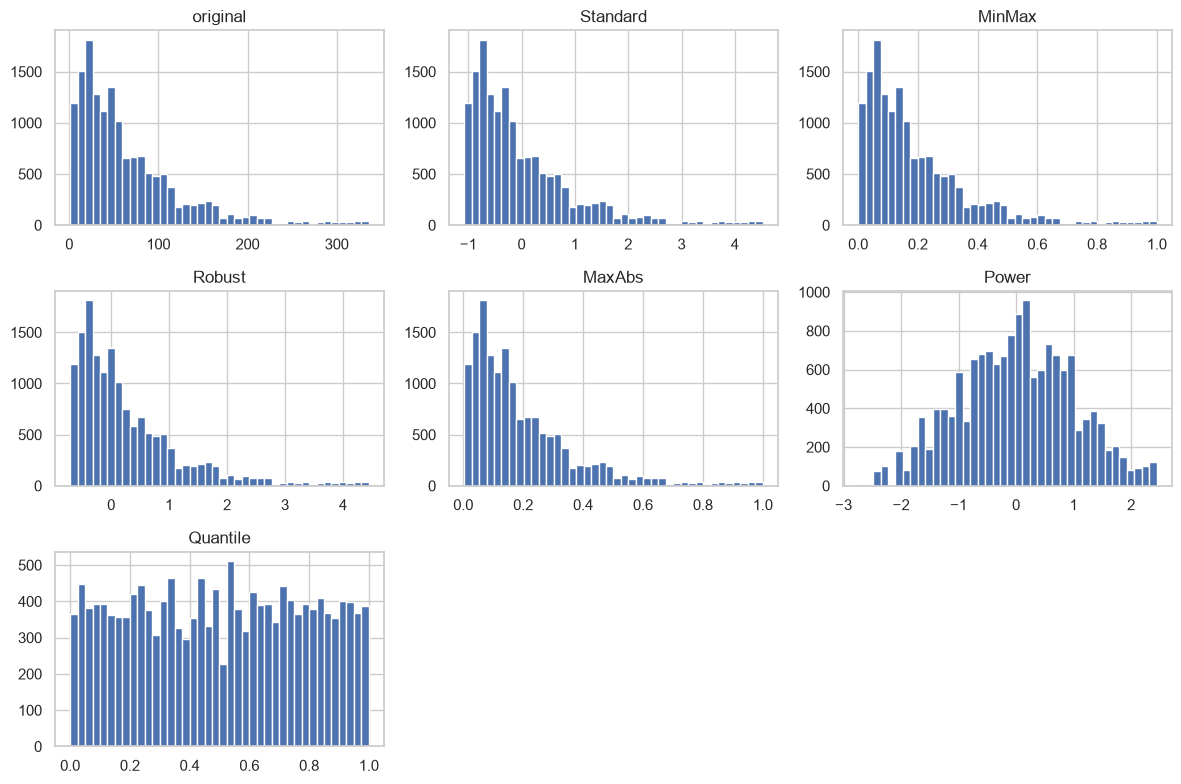

In [28]:
coluna_scaling = 'horas_formacao'
valores_scaling = X_train[[coluna_scaling]].dropna().astype(float)
scalers_demo = {
    'Standard': StandardScaler(), 'MinMax': MinMaxScaler(),
    'Robust': RobustScaler(), 'MaxAbs': MaxAbsScaler(),
    'Power': PowerTransformer(),
    'Quantile': QuantileTransformer(n_quantiles=min(1000, len(valores_scaling)),
                                   random_state=RANDOM_STATE),
}
comparacao_scaling = pd.DataFrame({'original': valores_scaling[coluna_scaling].to_numpy()})
for nome, scaler in scalers_demo.items():
    comparacao_scaling[nome] = scaler.fit_transform(valores_scaling).ravel()
display(comparacao_scaling.describe().T.round(3))
comparacao_scaling.hist(bins=40, figsize=(12, 8))
plt.tight_layout()
plt.show()

##### Análise e Interpretação

**Resposta:** As horas de formação são assimétricas e têm cauda longa. `RobustScaler` usa mediana e intervalo interquartil, sendo menos sensível a extremos. O escalonamento é útil para futuros modelos baseados em distância ou otimização; árvores não precisam dele.

**8.2 Scaler escolhido**
- Guardar a escolha em `SCALER` (nas aulas: `RobustScaler()`).

In [29]:
SCALER = RobustScaler()
print('Scaler escolhido:', type(SCALER).__name__)

Scaler escolhido: RobustScaler


### 9. Redução de dimensionalidade
<hr>

Reduzir o número de variáveis mantendo o máximo de informação (evita overfitting, reduz ruído, melhora velocidade — "maldição da dimensionalidade").

1. **Feature selection** — manter as variáveis mais relevantes (M3.02): correlação > 0,8, baixa variância (`VarianceThreshold`), testes estatísticos (`SelectKBest`), importância de um Random Forest, `RFE`
2. **Feature extraction** — criar novas componentes: **PCA** (sempre depois de escalonar)

***Objetivo:*** reduzir complexidade e multicolinearidade. Em datasets com poucas variáveis, esta etapa pode concluir que **não é necessário reduzir** — também é uma decisão válida.

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Seleção de variáveis e leakage</div>Os métodos que usam o target (<code>SelectKBest</code>, importância do Random Forest, <code>RFE</code>, correlação com o alvo) aplicam-se <b>só no treino</b> — nunca no dataset completo. Mesmo assim, se a seleção for feita aqui sobre todo o treino e depois se fizer validação cruzada na Fase 4 com as variáveis escolhidas, a CV fica <b>ligeiramente otimista</b>, porque os folds de validação já participaram na escolha. A forma mais rigorosa é colocar a seleção dentro do Pipeline (ex.: passo <code>SelectKBest</code>, com <code>k</code> afinado no GridSearch). Se a fizerem aqui, mencionem esta limitação na Fase 5.</div>

**9.1 Variância baixa**
- `VarianceThreshold` nas numéricas do treino; listar as variáveis quase constantes.

In [30]:
numericas_imputadas = pd.DataFrame(
    SimpleImputer(strategy=ESTRATEGIA_NUM).fit_transform(X_train[NUM_COLS]),
    columns=NUM_COLS, index=X_train.index
)
seletor_variancia = VarianceThreshold(threshold=0.001)
seletor_variancia.fit(numericas_imputadas)
baixa_variancia = [c for c, manter in zip(NUM_COLS, seletor_variancia.get_support()) if not manter]
print('Variáveis numéricas com variância <= 0,001:', baixa_variancia)
display(numericas_imputadas.var().sort_values().to_frame('variancia').round(4))

Variáveis numéricas com variância <= 0,001: []


,variancia
indice_desenvolvimento_cidade,0.0152
pouca_experiencia,0.1006
universidade_tempo_inteiro,0.1576
log_horas_formacao,0.8922
anos_experiencia_num,45.8787
horas_formacao,3577.8277


##### Análise e Interpretação

**Resposta:** A tabela mostra a variância de cada numérica depois de imputação ajustada no treino. A regra de variância baixa usa limite absoluto de 0,001, que depende da escala; não removemos automaticamente variáveis binárias raras por esse motivo.

**9.2 Correlação entre preditores**
- Listar os pares com |r| > 0,8 no treino.

In [31]:
correlacao = numericas_imputadas.corr()
pares_fortes = pd.DataFrame([
    {'variavel_1': a, 'variavel_2': b, 'correlacao': correlacao.loc[a, b]}
    for i, a in enumerate(NUM_COLS) for b in NUM_COLS[i + 1:]
    if abs(correlacao.loc[a, b]) > 0.8
])
display(pares_fortes)

,variavel_1,variavel_2,correlacao
0,horas_formacao,log_horas_formacao,0.864345


##### Análise e Interpretação

**Resposta:** `horas_formacao` e `log_horas_formacao` medem o mesmo fenómeno em escalas diferentes. Por parcimónia, a coluna original será retirada do pipeline, conservando a versão logarítmica. Outros pares acima de |r| = 0,8 devem ser avaliados pela tabela, sem remoção automática.

**9.3 Seleção por teste e por modelo (M3.02)**
- Sobre os dados de treino imputados e codificados: `SelectKBest` (`f_classif` / `f_regression`), importância de um Random Forest (`feature_importances_`) e `RFE` com Logistic/Linear Regression.
- Tabela comparativa.

In [32]:
# Comparação exploratória no treino, com amostra para manter RFE executável.
# Nenhuma seleção automática é aplicada ao pipeline final.
amostra_sel = X_train.sample(n=min(5000, len(X_train)), random_state=RANDOM_STATE)
y_sel = y_train.loc[amostra_sel.index]
pre_sel = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                      ('scaler', RobustScaler())]), NUM_COLS),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='Desconhecido')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), CAT_COLS),
], sparse_threshold=0)
matriz_sel = pre_sel.fit_transform(amostra_sel)
nomes_sel = pre_sel.get_feature_names_out()
k = min(20, matriz_sel.shape[1])
teste_f = SelectKBest(score_func=f_classif, k=k).fit(matriz_sel, y_sel)
floresta_sel = RandomForestClassifier(n_estimators=60, min_samples_leaf=5,
                                      random_state=RANDOM_STATE, n_jobs=1).fit(matriz_sel, y_sel)
rfe_sel = RFE(LogisticRegression(max_iter=300, solver='liblinear'),
              n_features_to_select=k, step=0.25).fit(matriz_sel, y_sel)
comparacao_selecao = pd.DataFrame({
    'variavel': nomes_sel,
    'F_score': np.nan_to_num(teste_f.scores_, nan=0),
    'top_F': teste_f.get_support(),
    'importancia_RF': floresta_sel.feature_importances_,
    'top_RFE': rfe_sel.support_,
}).sort_values('importancia_RF', ascending=False)
display(comparacao_selecao.head(25).round(4))

,variavel,F_score,top_F,importancia_RF,top_RFE
0,num__indice_desenvolvimento_cidade,619.1046,True,0.2135,True
68,cat__cidade_Zona_065,552.0013,True,0.1209,True
154,cat__dimensao_empresa_Desconhecido,366.5612,True,0.0858,True
156,cat__tipo_empresa_Desconhecido,265.4548,True,0.0594,False
2,num__anos_experiencia_num,180.2751,True,0.0517,False
3,num__log_horas_formacao,1.2894,False,0.0463,False
1,num__horas_formacao,6.5874,False,0.0459,False
157,cat__tipo_empresa_Empresa privada,162.7153,True,0.0267,False
128,cat__experiencia_relevante_Com experiência rel...,130.1788,True,0.0233,False
130,cat__inscricao_universidade_Curso a tempo inteiro,162.3661,True,0.0226,False


##### Análise e Interpretação

**Resposta:** A tabela compara um teste univariado, uma floresta e RFE numa amostra do treino. A importância pode diferir porque os métodos medem propriedades distintas e colunas correlacionadas repartem sinal. A escolha final das variáveis será validada na Fase 4; esta análise não utiliza o teste.

**9.4 PCA**
- Normalizar as numéricas do treino e aplicar `PCA()`; tabela da variância explicada e acumulada; nº de componentes para ≥ 95%; gráfico da variância acumulada.

,componente,variancia_explicada,acumulada
0,1,0.5303,0.5303
1,2,0.2370,0.7673
2,3,0.1121,0.8794
3,4,0.0547,0.9341
4,5,0.0360,0.9701
5,6,0.0299,1.0000


Componentes para 95%: 5 de 6


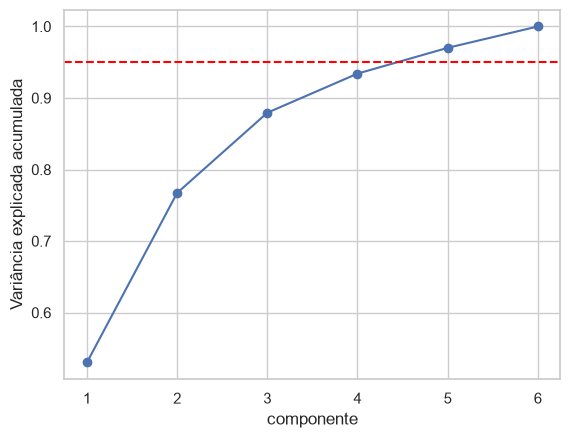

In [33]:
matriz_pca = RobustScaler().fit_transform(numericas_imputadas)
pca_demo = PCA().fit(matriz_pca)
variancia_pca = pd.DataFrame({
    'componente': np.arange(1, len(pca_demo.explained_variance_ratio_) + 1),
    'variancia_explicada': pca_demo.explained_variance_ratio_,
    'acumulada': np.cumsum(pca_demo.explained_variance_ratio_),
})
numero_95 = int(np.searchsorted(variancia_pca['acumulada'].to_numpy(), 0.95) + 1)
display(variancia_pca.round(4))
print('Componentes para 95%:', numero_95, 'de', len(NUM_COLS))
variancia_pca.plot(x='componente', y='acumulada', marker='o', legend=False)
plt.axhline(0.95, color='red', linestyle='--')
plt.ylabel('Variância explicada acumulada')
plt.show()

##### Análise e Interpretação

**Resposta:** A PCA é exploratória e utiliza apenas o treino. Mesmo que reduza dimensões, as componentes dificultam a interpretação do efeito da experiência, da cidade e das horas. Como o número de variáveis numéricas é pequeno, opta-se por não a incluir no pipeline final.

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Critério da variância acumulada: 70–80% (redução agressiva, exploração) · 85–90% (bom equilíbrio) · <b>95%</b> (conservador, muito usado) · 99% (perda mínima). Uma redução começa a ser interessante quando se reduzem 40–50% das variáveis mantendo 90–95% da variância. <b>Seleção</b> mantém variáveis interpretáveis; o <b>PCA</b> mantém mais informação mas as componentes perdem significado (M3.02).</div>

**9.5 Decisão**
- Atualizar `NUM_COLS`/`CAT_COLS` com as variáveis a remover e definir `USAR_PCA` (True/False).

In [34]:
# A versão log das horas retém o mesmo ordenamento. A flag da universidade
# está exatamente representada pelo One-Hot da coluna categórica original.
REMOVER_PREDITORES = ['horas_formacao', 'universidade_tempo_inteiro']
NUM_COLS = [c for c in NUM_COLS if c not in REMOVER_PREDITORES]
CAT_COLS = [c for c in CAT_COLS if c not in REMOVER_PREDITORES]
X_train = X_train.drop(columns=REMOVER_PREDITORES)
X_test = X_test.drop(columns=REMOVER_PREDITORES)
USAR_PCA = False
print('Preditores removidos:', REMOVER_PREDITORES)
print('Numéricas finais:', NUM_COLS)
print('Categóricas finais:', CAT_COLS)

Preditores removidos: ['horas_formacao', 'universidade_tempo_inteiro']
Numéricas finais: ['indice_desenvolvimento_cidade', 'anos_experiencia_num', 'log_horas_formacao', 'pouca_experiencia']
Categóricas finais: ['cidade', 'genero', 'experiencia_relevante', 'inscricao_universidade', 'nivel_educacao', 'area_formacao', 'dimensao_empresa', 'tipo_empresa', 'anos_desde_ultimo_emprego']


### 10. Pipeline final de preparação
<hr>

O `Pipeline` + `ColumnTransformer` junta todas as decisões anteriores num único objeto que:
- evita *data leakage* (é ajustado só no treino — e, na Fase 4, dentro de cada fold da validação cruzada);
- aplica exatamente as mesmas transformações a treino, teste e dados futuros;
- torna o processo reproduzível.

**10.1 Pipeline final de preparação (M3.02)**
- `ColumnTransformer` com:
  - `"num"`: `Pipeline` com imputação (`SimpleImputer(strategy=ESTRATEGIA_NUM, add_indicator=ADD_INDICATOR)`, ou `KNNImputer` se `"knn"`) + `SCALER` (+ PCA se `USAR_PCA`);
  - `"cat"`: `Pipeline` com imputação (`ESTRATEGIA_CAT`) + `OneHotEncoder(handle_unknown="ignore")`.
- `fit_transform` no treino e `transform` no teste; mostrar as dimensões e as primeiras linhas.

In [35]:
if ESTRATEGIA_NUM == 'knn':
    imputador_num = KNNImputer(add_indicator=ADD_INDICATOR)
else:
    imputador_num = SimpleImputer(strategy=ESTRATEGIA_NUM, add_indicator=ADD_INDICATOR)
etapas_num = [('imputer', imputador_num), ('scaler', SCALER)]
if USAR_PCA:
    etapas_num.append(('pca', PCA(n_components=0.95)))
prep = ColumnTransformer([
    ('num', Pipeline(etapas_num), NUM_COLS),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy=ESTRATEGIA_CAT, fill_value='Desconhecido')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), CAT_COLS),
], sparse_threshold=0, verbose_feature_names_out=True)
X_train_prepared = prep.fit_transform(X_train)
X_test_prepared = prep.transform(X_test)
NOMES_PREP = prep.get_feature_names_out()
print('Treino preparado:', X_train_prepared.shape)
print('Teste preparado:', X_test_prepared.shape)
display(pd.DataFrame(X_train_prepared[:5], columns=NOMES_PREP, index=X_train.index[:5]))

Treino preparado: (15326, 175)
Teste preparado: (3832, 175)


,num__indice_desenvolvimento_cidade,num__anos_experiencia_num,num__log_horas_formacao,num__pouca_experiencia,num__missingindicator_anos_experiencia_num,num__missingindicator_pouca_experiencia,cat__cidade_Zona_001,cat__cidade_Zona_002,cat__cidade_Zona_003,cat__cidade_Zona_004,cat__cidade_Zona_005,cat__cidade_Zona_006,cat__cidade_Zona_007,cat__cidade_Zona_008,cat__cidade_Zona_009,cat__cidade_Zona_010,cat__cidade_Zona_011,cat__cidade_Zona_012,cat__cidade_Zona_013,cat__cidade_Zona_014,cat__cidade_Zona_015,cat__cidade_Zona_016,cat__cidade_Zona_017,cat__cidade_Zona_018,cat__cidade_Zona_019,cat__cidade_Zona_020,cat__cidade_Zona_021,cat__cidade_Zona_022,cat__cidade_Zona_023,cat__cidade_Zona_024,cat__cidade_Zona_025,cat__cidade_Zona_026,cat__cidade_Zona_027,cat__cidade_Zona_028,cat__cidade_Zona_029,cat__cidade_Zona_030,cat__cidade_Zona_031,cat__cidade_Zona_032,cat__cidade_Zona_033,cat__cidade_Zona_034,cat__cidade_Zona_035,cat__cidade_Zona_036,cat__cidade_Zona_037,cat__cidade_Zona_038,cat__cidade_Zona_039,cat__cidade_Zona_040,cat__cidade_Zona_041,cat__cidade_Zona_042,cat__cidade_Zona_043,cat__cidade_Zona_044,cat__cidade_Zona_045,cat__cidade_Zona_046,cat__cidade_Zona_047,cat__cidade_Zona_048,cat__cidade_Zona_049,cat__cidade_Zona_050,cat__cidade_Zona_051,cat__cidade_Zona_052,cat__cidade_Zona_053,cat__cidade_Zona_054,cat__cidade_Zona_055,cat__cidade_Zona_056,cat__cidade_Zona_057,cat__cidade_Zona_058,cat__cidade_Zona_059,cat__cidade_Zona_060,cat__cidade_Zona_061,cat__cidade_Zona_062,cat__cidade_Zona_063,cat__cidade_Zona_064,cat__cidade_Zona_065,cat__cidade_Zona_066,cat__cidade_Zona_067,cat__cidade_Zona_068,cat__cidade_Zona_069,cat__cidade_Zona_070,cat__cidade_Zona_071,cat__cidade_Zona_072,cat__cidade_Zona_073,cat__cidade_Zona_074,cat__cidade_Zona_075,cat__cidade_Zona_076,cat__cidade_Zona_077,cat__cidade_Zona_078,cat__cidade_Zona_079,cat__cidade_Zona_080,cat__cidade_Zona_081,cat__cidade_Zona_082,cat__cidade_Zona_083,cat__cidade_Zona_084,cat__cidade_Zona_085,cat__cidade_Zona_086,cat__cidade_Zona_087,cat__cidade_Zona_088,cat__cidade_Zona_089,cat__cidade_Zona_090,cat__cidade_Zona_091,cat__cidade_Zona_092,cat__cidade_Zona_093,cat__cidade_Zona_094,cat__cidade_Zona_095,cat__cidade_Zona_096,cat__cidade_Zona_097,cat__cidade_Zona_098,cat__cidade_Zona_099,cat__cidade_Zona_100,cat__cidade_Zona_101,cat__cidade_Zona_102,cat__cidade_Zona_103,cat__cidade_Zona_104,cat__cidade_Zona_105,cat__cidade_Zona_106,cat__cidade_Zona_107,cat__cidade_Zona_108,cat__cidade_Zona_109,cat__cidade_Zona_110,cat__cidade_Zona_111,cat__cidade_Zona_112,cat__cidade_Zona_113,cat__cidade_Zona_114,cat__cidade_Zona_115,cat__cidade_Zona_116,cat__cidade_Zona_117,cat__cidade_Zona_118,cat__cidade_Zona_119,cat__cidade_Zona_120,cat__cidade_Zona_121,cat__cidade_Zona_122,cat__cidade_Zona_123,cat__genero_Desconhecido,cat__genero_Feminino,cat__genero_Masculino,cat__genero_Outro,cat__experiencia_relevante_Com experiência relevante,cat__experiencia_relevante_Sem experiência relevante,cat__inscricao_universidade_Curso a tempo inteiro,cat__inscricao_universidade_Curso a tempo parcial,cat__inscricao_universidade_Desconhecido,cat__inscricao_universidade_Não inscrito,cat__nivel_educacao_Desconhecido,cat__nivel_educacao_Doutoramento,cat__nivel_educacao_Ensino Básico,cat__nivel_educacao_Ensino Secundário,cat__nivel_educacao_Licenciatura,cat__nivel_educacao_Mestrado,cat__area_formacao_Artes,"cat__area_formacao_Ciência, Tecnologia, Engenharia e Matemática",cat__area_formacao_Desconhecido,cat__area_formacao_Gestão e Negócios,cat__area_formacao_Humanidades,cat__area_formacao_Outro,cat__area_formacao_Sem especialização,cat__dimensao_empresa_10 a 49,cat__dimensao_empresa_100 a 500,cat__dimensao_empresa_1000 a 4999,cat__dimensao_empresa_10000 ou mais,cat__dimensao_empresa_50 a 99,cat__dimensao_empresa_500 a 999,cat__dimensao_empresa_5000 a 9999,cat__dimensao_empresa_Desconhecido,cat__dimensao_empresa_Menos de 10,cat__tipo_empresa_Desconhecido,cat__tipo_empresa_Empresa privada,cat__tipo_empresa_ONG,cat__tipo_emp

##### Análise e Interpretação

**Resposta:** O número final de colunas é mostrado acima: inclui numéricas, indicadores de ausência e categorias One-Hot. Medianas, categorias e parâmetros do scaler foram aprendidos no treino e aplicados ao teste. O teste não participou no ajuste.

**10.2 Verificação**
- Confirmar que não há valores em falta nos dados preparados.

In [36]:
assert np.isfinite(X_train_prepared).all(), 'Treino preparado contém nulos ou infinitos.'
assert np.isfinite(X_test_prepared).all(), 'Teste preparado contém nulos ou infinitos.'
assert X_train_prepared.shape[1] == X_test_prepared.shape[1]
print('Verificação concluída: sem valores em falta; mesmas colunas no treino e teste.')

Verificação concluída: sem valores em falta; mesmas colunas no treino e teste.


### 11. Exportação dos dados preparados

Guardam-se os dados após as regras fixas (`*_train.csv`, `*_test.csv`), as versões transformadas (`*_prepared.csv`) e a configuração. Exportam-se também `*_train_raw.csv` e `*_test_raw.csv`, com as colunas originais, o identificador e o alvo codificado.

Na Fase 4 usam-se as entradas originais. As regras fixas de `preparacao_rh.py` passam a integrar o pipeline antes da imputação, do One-Hot e do modelo. A igualdade com a preparação deste notebook é verificada por código. Assim, treino, validação e previsão de novos casos seguem as mesmas regras. Os CSV já transformados servem para consulta; não se usam para ajustar modelos com validação cruzada.

**11. Exportação** (necessária para os notebooks 04, 05 e 06)
- Gravar em `Data/output/`:
  - classificação/regressão: `<PROJETO>_train.csv` e `<PROJETO>_test.csv` (X + target, **antes** das transformações aprendidas) e as versões `_prepared`;
  - clustering: `<PROJETO>_dataset_clustering.csv` (e `_prepared`).
- Gravar `Data/output/config_projeto.json` com: `PROJETO`, `TARGET`, `PROBLEM_TYPE`, `ID_COLS`, `NUM_COLS`, `CAT_COLS`, `RANDOM_STATE`, `TEST_SIZE`, `ESTRATEGIA_NUM`, `ESTRATEGIA_CAT`, `ADD_INDICATOR`, `SCALER` (nome da classe) e `USAR_PCA`.
- Gravar os parâmetros aprendidos no treino fora do Pipeline (limites de capping, mapeamentos de frequency/target encoding, medianas por grupo) em `Data/models/<PROJETO>_prep_params.json`, para reutilizar na Fase 6.

In [37]:
saida = Path('Data/output')
modelos = Path('Data/models')
base_train = X_train.copy().assign(**{TARGET: y_train})
base_test = X_test.copy().assign(**{TARGET: y_test})
base_train.to_csv(saida / f'{PROJETO}_train.csv', index=False)
base_test.to_csv(saida / f'{PROJETO}_test.csv', index=False)
pd.DataFrame(X_train_prepared, columns=NOMES_PREP).assign(**{TARGET: y_train.to_numpy()}).to_csv(
    saida / f'{PROJETO}_train_prepared.csv', index=False)
pd.DataFrame(X_test_prepared, columns=NOMES_PREP).assign(**{TARGET: y_test.to_numpy()}).to_csv(
    saida / f'{PROJETO}_test_prepared.csv', index=False)
configuracao = {
    'PROJETO': PROJETO, 'DATA_PATH': str(DATA_PATH), 'TARGET': TARGET,
    'PROBLEM_TYPE': PROBLEM_TYPE, 'ID_COLS': ID_COLS,
    'NUM_COLS': NUM_COLS, 'CAT_COLS': CAT_COLS,
    'RANDOM_STATE': RANDOM_STATE, 'TEST_SIZE': TEST_SIZE,
    'ESTRATEGIA_NUM': ESTRATEGIA_NUM, 'ESTRATEGIA_CAT': ESTRATEGIA_CAT,
    'ADD_INDICATOR': ADD_INDICATOR, 'SCALER': type(SCALER).__name__,
    'USAR_PCA': USAR_PCA,
    'FEATURES_NOVAS': FEATURES_NOVAS, 'REMOVER_PREDITORES': REMOVER_PREDITORES,
    'TARGET_MAP': {'Não': 0, 'Sim': 1},
}
(saida / 'config_projeto.json').write_text(
    json.dumps(configuracao, ensure_ascii=False, indent=2), encoding='utf-8')
(modelos / f'{PROJETO}_prep_params.json').write_text(
    json.dumps(parametros_fora_pipeline, ensure_ascii=False, indent=2), encoding='utf-8')
print('Ficheiros exportados para', saida.resolve())
display(pd.Series({p.name: p.stat().st_size for p in saida.iterdir() if p.is_file()}, name='bytes'))

# Preservar também as entradas originais e os identificadores dos dois conjuntos.
# A Fase 4 recebe estes dados e inclui as regras fixas num pipeline completo.
for nome, indices, alvo in [('train', X_train.index, y_train),
                             ('test', X_test.index, y_test)]:
    base_raw = df_raw.loc[indices].copy()
    base_raw[TARGET] = alvo
    base_raw.to_csv(saida / f'{PROJETO}_{nome}_raw.csv', index=False)
    df_raw.loc[indices, ID_COLS].to_csv(saida / f'{PROJETO}_{nome}_ids.csv', index=False)

from preparacao_rh import preparar_registos, COLUNAS_ORIGINAIS
for original, preparado in [(df_raw.loc[X_train.index], X_train),
                              (df_raw.loc[X_test.index], X_test)]:
    repetido = preparar_registos(original)[preparado.columns]
    pd.testing.assert_frame_equal(repetido, preparado, check_dtype=False)
print('Confirmado: as regras reutilizáveis reproduzem a preparação deste notebook.')
configuracao['RAW_FEATURES'] = COLUNAS_ORIGINAIS
configuracao['METRICA_PRINCIPAL'] = 'f1'
configuracao['LIMIAR'] = 0.5
configuracao['CV_FOLDS'] = 5
configuracao['METAS'] = {'f1': 0.50, 'recall': 0.60, 'roc_auc': 0.75}
(saida / 'config_projeto.json').write_text(
    json.dumps(configuracao, ensure_ascii=False, indent=2), encoding='utf-8')


Ficheiros exportados para C:\Users\Nuno\Documents\ChatGPT\Projeto Python\Projeto_RH_Versao_Atualizada_Arvore\Projeto\Data\output


config_projeto.json                                 1044
RH_Mudanca_Emprego_comparacao_modelos.csv            162
RH_Mudanca_Emprego_criterios_sucesso.csv             139
RH_Mudanca_Emprego_cv_folds_base.csv                 268
RH_Mudanca_Emprego_erros_segmentos.csv               219
RH_Mudanca_Emprego_exemplo_lote.csv                 1434
RH_Mudanca_Emprego_importancia_variaveis.csv        5524
RH_Mudanca_Emprego_limiares_treino.csv               945
RH_Mudanca_Emprego_Results.csv                    928254
RH_Mudanca_Emprego_resumo_validado.json              435
RH_Mudanca_Emprego_test.csv                       660502
RH_Mudanca_Emprego_test_ids.csv                    30670
RH_Mudanca_Emprego_test_prepared.csv             2849497
RH_Mudanca_Emprego_test_raw.csv                   631329
RH_Mudanca_Emprego_train.csv                     2648474
RH_Mudanca_Emprego_train_ids.csv                  122622
RH_Mudanca_Emprego_train_prepared.csv           11380516
RH_Mudanca_Emprego_train_raw.cs

Confirmado: as regras reutilizáveis reproduzem a preparação deste notebook.


1447

### 12. Síntese da Fase de Data Preparation

As transformações e decisões estão resumidas na tabela seguinte. As dimensões finais e a verificação de ausência de nulos encontram-se nas secções 10 e 11.

**Resposta:**

| # | Transformação | Variáveis | Justificação | Aprende com os dados? |
|---|---|---|---|---|
| 1 | Retirar identificador de `X` | `id_candidato` | Evitar que um código individual entre no modelo | Não |
| 2 | Normalizar texto e converter experiência | Categorias, `anos_experiencia` | Consistência dos tipos | Não |
| 3 | Codificar alvo | `procura_mudanca_emprego` | “Sim” é a classe positiva (1) | Não |
| 4 | Divisão estratificada 80/20 | Todas | Preservar proporções e reservar teste | Não |
| 5 | Criar variáveis | Horas, experiência, universidade | Representar assimetria e grupos relevantes | Não |
| 6 | Imputar mediana e adicionar indicadores | Numéricas | Tratar ausências sem perder linhas | Sim, no treino |
| 7 | Imputar categoria “Desconhecido” e One-Hot | Categóricas | Preservar ausência e evitar ordem artificial | Sim, no treino |
| 8 | `RobustScaler` | Numéricas | Reduzir influência dos valores extremos | Sim, no treino |
| 9 | Excluir preditores redundantes | `horas_formacao`, `universidade_tempo_inteiro` | Informação preservada por `log_horas_formacao` e One-Hot da inscrição universitária | Não |

O conjunto preparado tem as dimensões impressas na secção 10. Valores extremos plausíveis foram mantidos. A alta cardinalidade de `cidade` aumenta o número de colunas. A preparação antes do pipeline (`criar_features` e regras de limpeza) deve ser reaplicada a candidatos novos na Fase 6. Na Fase 4, o pipeline tem de ser reajustado **dentro de cada fold** da validação cruzada; os CSV `*_prepared` servem para consulta ou modelos sem validação cruzada do pré-processamento.

Na Fase 4, `preparacao_rh.preparar_registos` integra o modelo guardado. Esta função aplica apenas regras fixas, sem aprender estatísticas nem usar o alvo. Imputação, encoding e scaling são reajustados dentro de cada fold. A análise de seleção de variáveis e PCA foi apenas exploratória; não se usaram os rankings para escolher os preditores finais.

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Antes de avançar</div>Checklist de autoavaliação da fase<ul style="margin:4px 0 2px 0;"><li>Limpeza dos dados (missing, duplicados, inconsistências) justificada</li><li>Remoção explícita de colunas irrelevantes / identificadores</li><li>Engenharia de variáveis e encoding adequados ao tipo de variável</li><li>Definição explícita de <code>X</code> e <code>y</code></li><li>Divisão treino/teste correta (estratificada em classificação)</li><li>Divisão adequada à estrutura dos dados (aleatória / estratificada / temporal / por grupo)</li><li>Transformações ajustadas no treino — sem <i>data leakage</i></li><li>Nenhuma decisão tomada com base no conjunto de teste</li><li>Dados preparados e configuração exportados</li></ul></div>

[← Fase 2: Entendimento dos Dados](02_P_data_understanding.ipynb) &nbsp;&nbsp;|&nbsp;&nbsp; [Fase 4: Modelação →](04_modeling.ipynb)

<div style="border-left:7px solid #1A59FD; background:#F3F6FF; color:#0A2540; padding:6px 14px; border-radius:4px; font-size:12px; font-family:Segoe UI, Arial, sans-serif;">Cegid Academy &nbsp;·&nbsp; AiDAPT &nbsp;·&nbsp; Template CRISP-DM v2.0 · versão formandos</div>